# MLP v2 — Strategy B

**Why a v2?** v1 (`06_train_mlp.ipynb`) suffered from two issues we diagnosed and fixed here:

1. **MPS NaN bug.** PyTorch's Apple-Silicon GPU backend intermittently produced `NaN` in vanilla-BCE training (`BatchNorm1d` + reduction kernels). One bad batch → params poisoned → all subsequent epochs `NaN`. v2 runs on **CPU** (same speed for this small MLP: ~2.4 s/epoch) and adds gradient clipping + skip-batch as a defense in depth.

2. **Wrong selection metric.** v1 early-stopped on `val_macro_F1 @ threshold 0.5`. Vanilla BCE on imbalanced data produces calibrated probabilities far below 0.5 for rare classes — F1 at 0.5 reads as ~0 even when the model is improving. v2 selects on **val mean-AP (mAP)**, the standard threshold-free multi-label metric, which actually tracks model quality during training.

**Other tweaks:** `min_epochs=15`, `patience=7`, `max_epochs=60` — give the slower configs (C3 focal especially) room to converge.

**Same protocol** otherwise: 3 trained configs + 1 threshold-tuning config; val-only selection; test touched exactly once.

Strategy B — augmented training set.

## Cell 1 — Setup

CPU device is **forced** here. MPS is faster on big convnets but for our ~700k-param MLP on 100k rows, CPU runs in 2.4 s/epoch (vs 2.3 s on MPS) — we lose nothing and gain numerical stability + reproducibility.

In [1]:
# ============================================================================
# CELL 1 — Setup (v2)
# ============================================================================
import sys
from pathlib import Path

_SHARED = Path.cwd().resolve().parents[1] / '_shared'
if str(_SHARED) not in sys.path:
    sys.path.insert(0, str(_SHARED))

import json
import time
import warnings
import random
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import average_precision_score  # for mAP

from data import load_splits, find_root, load_config
from eval import (
    predict_with_threshold, tune_thresholds_on_val,
    classification_report, macro_f1 as macro_f1_np,
)
from imbalance import compute_class_weights, make_focal_loss
from plot import plot_per_class_f1, plot_loss_curves, plot_confusion_matrices

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

# --- Config ---------------------------------------------------------------
STRATEGY    = 'B'
MODEL_NAME  = 'mlp'
NOTEBOOK_ID = '07'              # v2 results -> 07_mlp.json
RANDOM_SEED = 42

# Architecture (unchanged from v1)
HIDDEN_SIZES = (512, 256, 128)
DROPOUT      = 0.3

# Optimization
BATCH_SIZE       = 512
LR               = 1e-3
WEIGHT_DECAY     = 1e-4
MAX_EPOCHS       = 60        # was 50
MIN_EPOCHS       = 15        # was 10 — give focal/BCE time to converge
PATIENCE         = 7         # was 5
GRAD_CLIP_NORM   = 1.0       # NEW — defense against transient explosions
SELECTION_METRIC = 'val_mAP' # NEW — selection driver; macro F1 still reported

# --- Reproducibility ------------------------------------------------------
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(False)  # BN1d backward isn't deterministic; we accept

set_seed(RANDOM_SEED)

# --- Device — FORCED CPU --------------------------------------------------
DEVICE = torch.device('cpu')
# Note: MPS would be ~5% faster but has documented intermittent NaN bugs
# with BatchNorm1d. See diagnosis in conversation log / handoff.

# --- Paths ---------------------------------------------------------------
ROOT        = find_root()
CONFIG      = load_config()
ARTIFACTS   = ROOT / CONFIG['paths'][f'strategy_{STRATEGY.lower()}_artifacts']
RESULTS_DIR = ARTIFACTS / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Strategy:    {STRATEGY}")
print(f"Model:       {MODEL_NAME}  (notebook v2)")
print(f"Device:      {DEVICE}  (forced — MPS NaN workaround)")
print(f"Hidden:      {HIDDEN_SIZES} | dropout={DROPOUT}")
print(f"Optim:       AdamW(lr={LR}, wd={WEIGHT_DECAY}) + CosineAnnealing | grad_clip={GRAD_CLIP_NORM}")
print(f"Train:       batch={BATCH_SIZE}, max_epochs={MAX_EPOCHS}, min_epochs={MIN_EPOCHS}, patience={PATIENCE}")
print(f"Selection:   {SELECTION_METRIC}  (threshold-free; macro F1 still scored)")
print(f"Results dir: {RESULTS_DIR}")

Strategy:    B
Model:       mlp  (notebook v2)
Device:      cpu  (forced — MPS NaN workaround)
Hidden:      (512, 256, 128) | dropout=0.3
Optim:       AdamW(lr=0.001, wd=0.0001) + CosineAnnealing | grad_clip=1.0
Train:       batch=512, max_epochs=60, min_epochs=15, patience=7
Selection:   val_mAP  (threshold-free; macro F1 still scored)
Results dir: /Users/amrabdullah/AI_2026ss/mlpc/strategy_B_with_aug/artifacts/results


## Cell 2 — Load data

Identical to v1. Uses the same pre-scaled `splits.npz`.

In [2]:
# ============================================================================
# CELL 2 — Load data
# ============================================================================
d = load_splits(STRATEGY)
print(d.summary())

class_names = list(d.class_names)
D = d.D
C = d.C

X_train_t = torch.from_numpy(d.X_train.astype(np.float32))
Y_train_t = torch.from_numpy(d.Y_train.astype(np.float32))
X_val_t   = torch.from_numpy(d.X_val.astype(np.float32))
Y_val_t   = torch.from_numpy(d.Y_val.astype(np.float32))
X_test_t  = torch.from_numpy(d.X_test.astype(np.float32))
Y_test_t  = torch.from_numpy(d.Y_test.astype(np.float32))

train_ds = TensorDataset(X_train_t, Y_train_t)

print(f"\nClass priors (train positive rate):")
priors = d.Y_train.mean(axis=0)
for c, cls in enumerate(class_names):
    print(f"  {cls:<30s} {priors[c]*100:5.2f}%  (n_pos={int(d.Y_train[:,c].sum()):>6d})")

Strategy B
  X_train: (114526, 960)  Y_train: (114526, 15)
  X_val:   (34245, 960)  Y_val:   (34245, 15)
  X_test:  (33828, 960)  Y_test:  (33828, 15)
  D = 960 features, C = 15 classes
  train composition: 100,166 real + 14,360 aug = 114,526 (+14.3% of real)

Class priors (train positive rate):
  bell_ringing                    3.31%  (n_pos=  3796)
  coffee_machine                  4.57%  (n_pos=  5233)
  cutlery_dishes                  5.32%  (n_pos=  6090)
  door_open_close                 3.58%  (n_pos=  4102)
  footsteps                      10.32%  (n_pos= 11818)
  keyboard_typing                 8.07%  (n_pos=  9237)
  keychain                        4.08%  (n_pos=  4670)
  light_switch                    0.89%  (n_pos=  1019)
  microwave                       6.07%  (n_pos=  6950)
  phone_ringing                   5.67%  (n_pos=  6488)
  running_water                  11.58%  (n_pos= 13259)
  toilet_flushing                 4.28%  (n_pos=  4900)
  vacuum_cleaner               

## Cell 3 — Model & training utilities (v2)

**Two changes vs v1:**

1. **Selection on `val mean-AP`.** Average Precision is the area under the per-class P-R curve at every threshold; it answers "given calibrated probabilities, how separable are positives from negatives?" *Without* committing to any threshold. We mean it across classes (macro-AP) so rare classes count equally. This is the right early-stopping signal when threshold tuning is applied downstream.

2. **NaN guards.** Skip any batch whose loss isn't finite (track the count); always `clip_grad_norm_(1.0)` before the optimizer step. These are cheap and stop any single bad batch from poisoning the whole model — useful even on CPU as defense in depth.

We still log `val_loss` and `val_macro_F1@0.5` each epoch for diagnostics, just don't select on them.

In [3]:
# ============================================================================
# CELL 3 — Model + training utilities (v2)
# ============================================================================
class MLP(nn.Module):
    def __init__(self, in_dim: int, out_dim: int,
                 hidden_sizes=(512, 256, 128), dropout=0.3):
        super().__init__()
        layers = []
        prev = in_dim
        for h in hidden_sizes:
            layers += [
                nn.Linear(prev, h),
                nn.BatchNorm1d(h),
                nn.ReLU(inplace=True),
                nn.Dropout(dropout),
            ]
            prev = h
        layers.append(nn.Linear(prev, out_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


@torch.no_grad()
def predict_probs(model, X_t, batch_size=4096, device=DEVICE):
    model.eval()
    out = []
    for i in range(0, X_t.shape[0], batch_size):
        xb = X_t[i:i+batch_size].to(device)
        out.append(torch.sigmoid(model(xb)).cpu())
    return torch.cat(out, 0).numpy()


def macro_average_precision(Y_true: np.ndarray, probs: np.ndarray) -> float:
    """Mean per-class AP. Robust to class imbalance, threshold-free."""
    aps = []
    for c in range(Y_true.shape[1]):
        if Y_true[:, c].sum() == 0:
            continue
        aps.append(average_precision_score(Y_true[:, c], probs[:, c]))
    return float(np.mean(aps))


def train_one_config(
    *,
    loss_fn,
    config_name: str,
    seed: int = RANDOM_SEED,
):
    """Train MLP with given loss; select on val mAP. Return rich result dict."""
    set_seed(seed)

    model = MLP(D, C, hidden_sizes=HIDDEN_SIZES, dropout=DROPOUT).to(DEVICE)
    opt   = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=MAX_EPOCHS)

    loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=0, drop_last=False,
    )

    history = {
        'train_loss': [], 'val_loss': [],
        'val_mAP':    [], 'val_macro_f1_at_0.5': [],
    }
    best_mAP, best_state, best_epoch = -1.0, None, -1
    epochs_since_improvement = 0
    total_skipped = 0

    print(f"--- [{config_name}] training on {DEVICE} ---")
    t0 = time.time()

    for epoch in range(1, MAX_EPOCHS + 1):
        # ---- Train ----
        model.train()
        total_loss, n_seen, skipped = 0.0, 0, 0
        for xb, yb in loader:
            xb = xb.to(DEVICE); yb = yb.to(DEVICE)
            logits = model(xb)
            loss = loss_fn(logits, yb)

            if not torch.isfinite(loss):
                skipped += 1
                opt.zero_grad(set_to_none=True)
                continue

            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP_NORM)
            opt.step()

            total_loss += loss.item() * xb.shape[0]
            n_seen += xb.shape[0]

        sched.step()
        total_skipped += skipped
        train_loss = total_loss / max(n_seen, 1)

        # ---- Eval on val ----
        val_probs = predict_probs(model, X_val_t)
        val_pred  = (val_probs >= 0.5).astype(np.int8)
        val_f1_at_0_5 = macro_f1_np(d.Y_val, val_pred)
        val_mAP_now  = macro_average_precision(d.Y_val, val_probs)

        # val loss
        model.eval()
        with torch.no_grad():
            vloss_total, vn = 0.0, 0
            for i in range(0, X_val_t.shape[0], 8192):
                xb = X_val_t[i:i+8192].to(DEVICE)
                yb = Y_val_t[i:i+8192].to(DEVICE)
                vl = loss_fn(model(xb), yb)
                if torch.isfinite(vl):
                    vloss_total += vl.item() * xb.shape[0]
                    vn += xb.shape[0]
            val_loss = vloss_total / max(vn, 1)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_mAP'].append(val_mAP_now)
        history['val_macro_f1_at_0.5'].append(val_f1_at_0_5)

        improved = val_mAP_now > best_mAP + 1e-6
        marker = "  *" if improved else ""
        skip_str = f"  (skipped {skipped} NaN batches)" if skipped else ""
        print(f"  ep {epoch:3d} | tr_loss {train_loss:.4f} | va_loss {val_loss:.4f} "
              f"| val_mAP {val_mAP_now:.4f} | val_F1@0.5 {val_f1_at_0_5:.4f}{marker}{skip_str}")

        if improved:
            best_mAP = val_mAP_now
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            best_epoch = epoch
            epochs_since_improvement = 0
        else:
            epochs_since_improvement += 1
            if epoch >= MIN_EPOCHS and epochs_since_improvement >= PATIENCE:
                print(f"  early stop @ epoch {epoch} (best mAP={best_mAP:.4f} @ ep {best_epoch})")
                break

    elapsed = time.time() - t0
    print(f"--- [{config_name}] done in {elapsed:.1f}s  "
          f"| best val mAP = {best_mAP:.4f} @ ep {best_epoch}  "
          f"| total NaN batches skipped = {total_skipped} ---\n")

    # Restore best
    model.load_state_dict(best_state)
    val_probs_best = predict_probs(model, X_val_t)
    val_macro_f1_at_0_5 = macro_f1_np(d.Y_val, (val_probs_best >= 0.5).astype(np.int8))

    return {
        'model':                model,
        'history':              history,
        'best_val_mAP':         float(best_mAP),
        'best_val_macro_f1':    float(val_macro_f1_at_0_5),  # at threshold 0.5
        'best_epoch':           int(best_epoch),
        'elapsed':              float(elapsed),
        'val_probs':            val_probs_best,
        'config_name':          config_name,
        'total_skipped':        int(total_skipped),
    }

## Cell 4 — Config 1: Vanilla BCE

Same as v1 but with v2's training loop. Note this config will likely have low `val_macro_F1@0.5` even when training well — its calibrated probabilities sit below 0.5 for rare classes. mAP is the metric that actually tracks its progress.

In [4]:
# ============================================================================
# CELL 4 — Config 1: Vanilla BCE
# ============================================================================
loss_c1 = nn.BCEWithLogitsLoss()
res_c1 = train_one_config(loss_fn=loss_c1, config_name='C1_vanilla_bce')

--- [C1_vanilla_bce] training on cpu ---
  ep   1 | tr_loss 0.1965 | va_loss 0.1094 | val_mAP 0.5047 | val_F1@0.5 0.3882  *
  ep   2 | tr_loss 0.1059 | va_loss 0.1007 | val_mAP 0.5303 | val_F1@0.5 0.4431  *
  ep   3 | tr_loss 0.0957 | va_loss 0.0986 | val_mAP 0.5476 | val_F1@0.5 0.4666  *
  ep   4 | tr_loss 0.0895 | va_loss 0.0984 | val_mAP 0.5579 | val_F1@0.5 0.4796  *
  ep   5 | tr_loss 0.0853 | va_loss 0.0984 | val_mAP 0.5590 | val_F1@0.5 0.4937  *
  ep   6 | tr_loss 0.0814 | va_loss 0.0966 | val_mAP 0.5642 | val_F1@0.5 0.5001  *
  ep   7 | tr_loss 0.0778 | va_loss 0.0987 | val_mAP 0.5604 | val_F1@0.5 0.4968
  ep   8 | tr_loss 0.0746 | va_loss 0.0980 | val_mAP 0.5680 | val_F1@0.5 0.5140  *
  ep   9 | tr_loss 0.0721 | va_loss 0.1001 | val_mAP 0.5659 | val_F1@0.5 0.5203
  ep  10 | tr_loss 0.0697 | va_loss 0.1013 | val_mAP 0.5601 | val_F1@0.5 0.5063
  ep  11 | tr_loss 0.0672 | va_loss 0.1021 | val_mAP 0.5677 | val_F1@0.5 0.5274
  ep  12 | tr_loss 0.0651 | va_loss 0.1021 | val_mAP 0.569

## Cell 5 — Config 2: pos-weighted BCE (`sqrt_inverse_freq`)

Per-class positive-class boost; rare classes get larger weight, common stay near 1×. Clipped to [0.5, 30] to avoid the destabilization that `balanced` (370× for light_switch) would cause.

In [5]:
# ============================================================================
# CELL 5 — Config 2: pos-weighted BCE
# ============================================================================
pos_w_np = compute_class_weights(d.Y_train, kind='sqrt_inverse_freq', clip=(0.5, 30.0))
print("pos_weight (sqrt_inverse_freq, clipped):")
for c, cls in enumerate(class_names):
    print(f"  {cls:<30s} {pos_w_np[c]:7.3f}")

pos_w_t = torch.as_tensor(pos_w_np, dtype=torch.float32, device=DEVICE)
loss_c2 = nn.BCEWithLogitsLoss(pos_weight=pos_w_t)
res_c2 = train_one_config(loss_fn=loss_c2, config_name='C2_pos_weighted_bce')

pos_weight (sqrt_inverse_freq, clipped):
  bell_ringing                     5.493
  coffee_machine                   4.678
  cutlery_dishes                   4.337
  door_open_close                  5.284
  footsteps                        3.113
  keyboard_typing                  3.521
  keychain                         4.952
  light_switch                    10.601
  microwave                        4.059
  phone_ringing                    4.201
  running_water                    2.939
  toilet_flushing                  4.835
  vacuum_cleaner                   4.119
  wardrobe_drawer_open_close       5.272
  window_open_close                5.360
--- [C2_pos_weighted_bce] training on cpu ---
  ep   1 | tr_loss 0.3533 | va_loss 0.2664 | val_mAP 0.5158 | val_F1@0.5 0.5016  *
  ep   2 | tr_loss 0.2500 | va_loss 0.2570 | val_mAP 0.5262 | val_F1@0.5 0.5156  *
  ep   3 | tr_loss 0.2290 | va_loss 0.2513 | val_mAP 0.5475 | val_F1@0.5 0.5283  *
  ep   4 | tr_loss 0.2149 | va_loss 0.2526 | val_

## Cell 6 — Config 3: Focal loss (γ = 2)

Down-weights easy examples (already-confident-correct), redirecting gradient to hard ones. Clean variant — no extra pos_weight stacked on top, so this is an apples-to-apples comparison vs C2.

In [6]:
# ============================================================================
# CELL 6 — Config 3: focal loss
# ============================================================================
loss_c3 = make_focal_loss(gamma=2.0, pos_weight=None).to(DEVICE)
res_c3 = train_one_config(loss_fn=loss_c3, config_name='C3_focal_g2')

--- [C3_focal_g2] training on cpu ---
  ep   1 | tr_loss 0.0471 | va_loss 0.0298 | val_mAP 0.5065 | val_F1@0.5 0.4237  *
  ep   2 | tr_loss 0.0291 | va_loss 0.0281 | val_mAP 0.5289 | val_F1@0.5 0.4550  *
  ep   3 | tr_loss 0.0267 | va_loss 0.0278 | val_mAP 0.5408 | val_F1@0.5 0.4696  *
  ep   4 | tr_loss 0.0251 | va_loss 0.0276 | val_mAP 0.5517 | val_F1@0.5 0.4735  *
  ep   5 | tr_loss 0.0239 | va_loss 0.0278 | val_mAP 0.5520 | val_F1@0.5 0.4827  *
  ep   6 | tr_loss 0.0229 | va_loss 0.0277 | val_mAP 0.5569 | val_F1@0.5 0.4904  *
  ep   7 | tr_loss 0.0220 | va_loss 0.0282 | val_mAP 0.5519 | val_F1@0.5 0.4909
  ep   8 | tr_loss 0.0211 | va_loss 0.0280 | val_mAP 0.5635 | val_F1@0.5 0.5095  *
  ep   9 | tr_loss 0.0205 | va_loss 0.0286 | val_mAP 0.5620 | val_F1@0.5 0.5143
  ep  10 | tr_loss 0.0198 | va_loss 0.0286 | val_mAP 0.5605 | val_F1@0.5 0.5079
  ep  11 | tr_loss 0.0192 | va_loss 0.0293 | val_mAP 0.5662 | val_F1@0.5 0.5242  *
  ep  12 | tr_loss 0.0185 | va_loss 0.0289 | val_mAP 0.570

## Cell 7 — Config 4: best base + per-class threshold tuning

We pick the mAP winner among C1/C2/C3 (best-calibrated probabilities) and apply per-class threshold tuning on val. Threshold tuning was consistently the single highest-impact lever for the tree models (XGBoost A: +0.08 macro F1 from this step alone).

In [7]:
# ============================================================================
# CELL 7 — Config 4: per-class threshold tuning on the mAP winner
# ============================================================================
all_configs = {1: res_c1, 2: res_c2, 3: res_c3}

print("Per-config summary (val):")
print(f"  {'Config':<24s} {'mAP':>8s}  {'F1@0.5':>8s}  {'best_ep':>8s}")
for k, r in all_configs.items():
    print(f"  C{k} {r['config_name']:<22s} {r['best_val_mAP']:>8.4f}  {r['best_val_macro_f1']:>8.4f}  {r['best_epoch']:>8d}")

# Base = mAP winner (best-calibrated probs)
base_id = max(all_configs, key=lambda k: all_configs[k]['best_val_mAP'])
base    = all_configs[base_id]
print(f"\nBase for threshold tuning: C{base_id} ({base['config_name']})  "
      f"val_mAP={base['best_val_mAP']:.4f}")

thr_df = tune_thresholds_on_val(
    base['val_probs'], d.Y_val,
    grid=np.arange(0.05, 0.96, 0.01),
    class_names=class_names,
)
winning_thresholds = thr_df.loc[class_names, 'threshold'].values.astype(float)

val_pred_c4 = predict_with_threshold(base['val_probs'], winning_thresholds)
val_f1_c4   = macro_f1_np(d.Y_val, val_pred_c4)
print(f"\nC4 val macro F1 (tuned): {val_f1_c4:.4f}  "
      f"(C{base_id} @ 0.5 was {base['best_val_macro_f1']:.4f}; Δ = {val_f1_c4 - base['best_val_macro_f1']:+.4f})")

print("\nPer-class thresholds:")
print(thr_df.loc[class_names, ['threshold', 'val_f1', 'val_support']].to_string())

Per-config summary (val):
  Config                        mAP    F1@0.5   best_ep
  C1 C1_vanilla_bce           0.5695    0.5313        12
  C2 C2_pos_weighted_bce      0.5664    0.5405        11
  C3 C3_focal_g2              0.5709    0.5303        12

Base for threshold tuning: C3 (C3_focal_g2)  val_mAP=0.5709

C4 val macro F1 (tuned): 0.5649  (C3 @ 0.5 was 0.5303; Δ = +0.0346)

Per-class thresholds:
                            threshold  val_f1  val_support
class                                                     
bell_ringing                     0.44  0.4746          480
coffee_machine                   0.55  0.6153         1073
cutlery_dishes                   0.46  0.6224         1828
door_open_close                  0.42  0.3955         1177
footsteps                        0.43  0.5442         4033
keyboard_typing                  0.46  0.7629         3107
keychain                         0.45  0.6072         1553
light_switch                     0.26  0.2320          140
micr

## Cell 8 — Pick overall winner on macro F1, evaluate on test once

mAP picked the *base* for threshold tuning. Now we pick the **final** winner by `val_macro_F1` (the report metric), evaluate on test once.

In [8]:
# ============================================================================
# CELL 8 — Final winner on val macro F1, evaluate on test ONCE
# ============================================================================
val_scores_macro_f1 = {
    1: res_c1['best_val_macro_f1'],
    2: res_c2['best_val_macro_f1'],
    3: res_c3['best_val_macro_f1'],
    4: float(val_f1_c4),
}
val_scores_mAP = {
    1: res_c1['best_val_mAP'],
    2: res_c2['best_val_mAP'],
    3: res_c3['best_val_mAP'],
    4: None,   # mAP not redefined by thresholding
}
print("Val macro F1 by config:")
for k, v in val_scores_macro_f1.items():
    map_str = f"  (mAP={val_scores_mAP[k]:.4f})" if val_scores_mAP[k] is not None else "  (mAP=base)"
    print(f"  C{k}: F1={v:.4f}{map_str}")

winner = max(val_scores_macro_f1, key=val_scores_macro_f1.get)
print(f"\nWinner: C{winner}  (val macro F1 = {val_scores_macro_f1[winner]:.4f})")

# ---- Winning val report ----
def report_for_config(config_id):
    if config_id == 1:
        probs, thr = res_c1['val_probs'], 0.5
    elif config_id == 2:
        probs, thr = res_c2['val_probs'], 0.5
    elif config_id == 3:
        probs, thr = res_c3['val_probs'], 0.5
    elif config_id == 4:
        probs, thr = base['val_probs'], winning_thresholds
    return classification_report(d.Y_val, predict_with_threshold(probs, thr), class_names)

report_val_winner = report_for_config(winner)
print("\nWinning val report:")
print(report_val_winner.loc[class_names + ['macro avg', 'micro avg', 'weighted avg']]
      .to_string())

# ---- Test eval ONCE ----
if winner == 1:
    test_model, test_thr = res_c1['model'], 0.5
elif winner == 2:
    test_model, test_thr = res_c2['model'], 0.5
elif winner == 3:
    test_model, test_thr = res_c3['model'], 0.5
else:  # 4
    test_model, test_thr = base['model'], winning_thresholds

test_probs = predict_probs(test_model, X_test_t)
test_pred  = predict_with_threshold(test_probs, test_thr)
report_test = classification_report(d.Y_test, test_pred, class_names)

print(f"\n=== TEST (Strategy {STRATEGY}, C{winner}) ===")
print(report_test.loc[class_names + ['macro avg', 'micro avg', 'weighted avg']]
      .to_string())

Val macro F1 by config:
  C1: F1=0.5313  (mAP=0.5695)
  C2: F1=0.5405  (mAP=0.5664)
  C3: F1=0.5303  (mAP=0.5709)
  C4: F1=0.5649  (mAP=base)

Winner: C4  (val macro F1 = 0.5649)

Winning val report:
                            precision  recall      f1  support
class                                                         
bell_ringing                   0.5185  0.4375  0.4746    480.0
coffee_machine                 0.7513  0.5210  0.6153   1073.0
cutlery_dishes                 0.6300  0.6149  0.6224   1828.0
door_open_close                0.3388  0.4749  0.3955   1177.0
footsteps                      0.4808  0.6268  0.5442   4033.0
keyboard_typing                0.8287  0.7068  0.7629   3107.0
keychain                       0.6385  0.5789  0.6072   1553.0
light_switch                   0.1815  0.3214  0.2320    140.0
microwave                      0.6693  0.6738  0.6715   2253.0
phone_ringing                  0.7370  0.6352  0.6824   2122.0
running_water                  0.8001  0.803

## Cell 9 — Plots

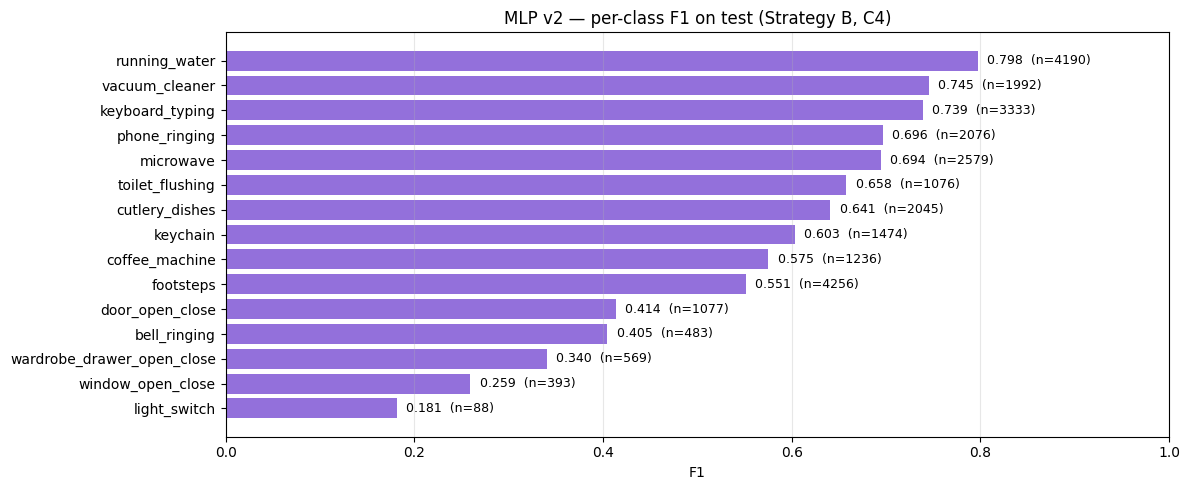

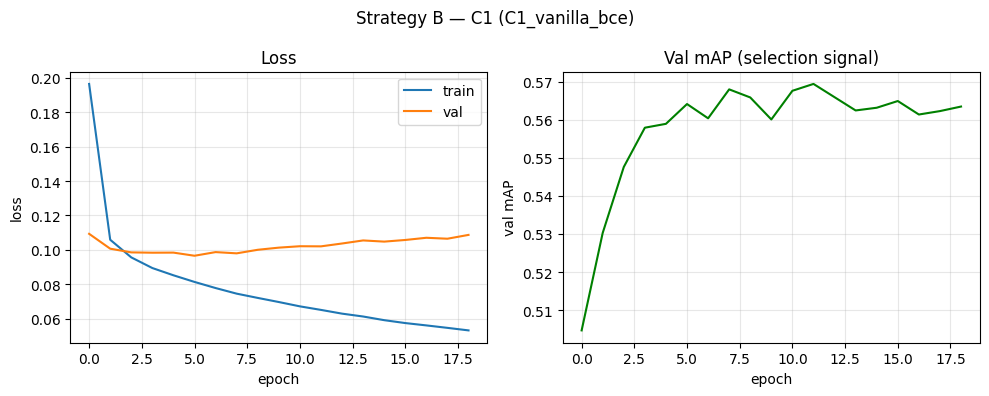

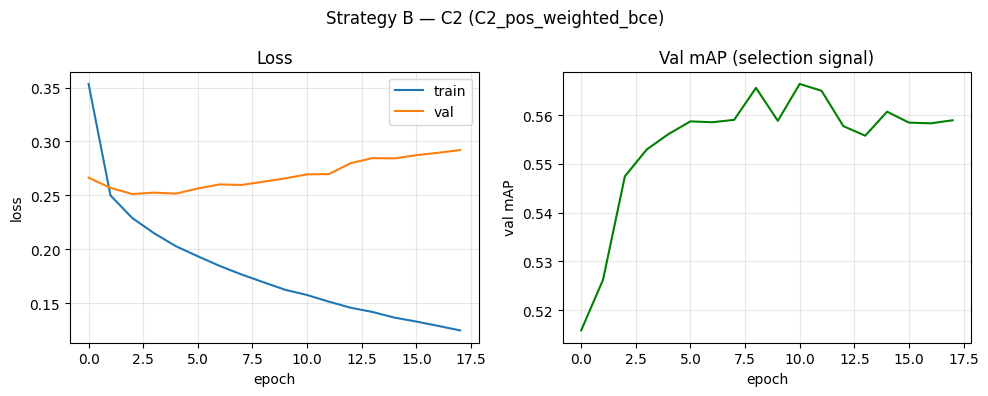

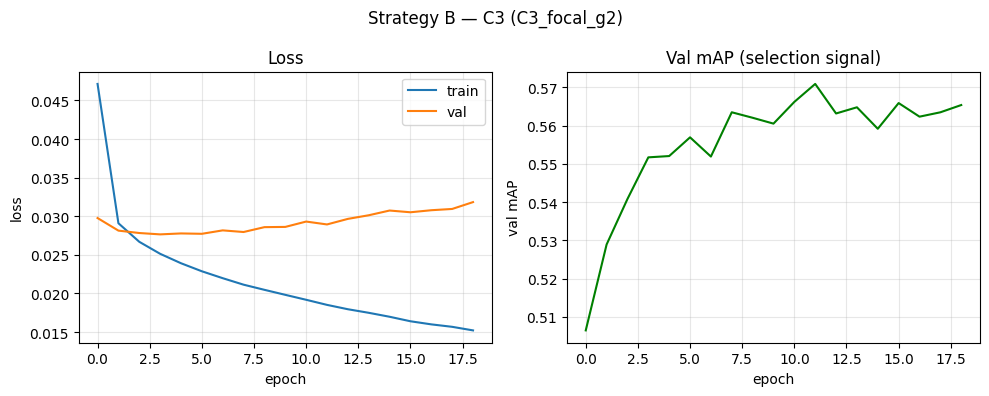

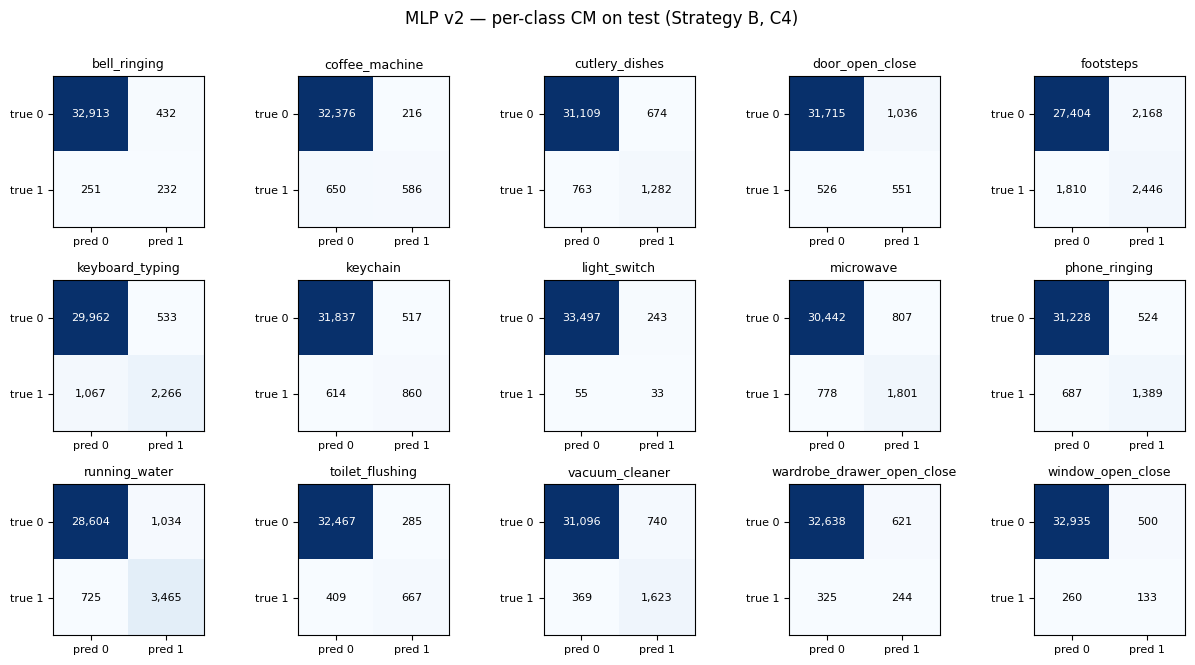

In [9]:
# ============================================================================
# CELL 9 — Plots
# ============================================================================
fig, ax = plot_per_class_f1(
    report_test, class_names=class_names,
    title=f"MLP v2 — per-class F1 on test (Strategy {STRATEGY}, C{winner})",
    color='mediumpurple',
)
fig.savefig(RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}_per_class_f1.png", dpi=130, bbox_inches='tight')
plt.show()

# Training curves for each config — note val_mAP is the selection signal
for cid, res in all_configs.items():
    # Adapt plot_loss_curves: it expects 'val_macro_f1' or 'val_f1' key; we have val_mAP
    h = dict(res['history'])
    h['val_macro_f1'] = h['val_mAP']     # rename so plotter picks it up
    fig, axes = plot_loss_curves(h, title=f"Strategy {STRATEGY} — C{cid} ({res['config_name']})")
    axes[1].set_ylabel('val mAP')
    axes[1].set_title('Val mAP (selection signal)')
    fig.savefig(RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}_curves_c{cid}.png", dpi=110, bbox_inches='tight')
    plt.show()

fig, _ = plot_confusion_matrices(
    d.Y_test, test_pred, class_names,
    title=f"MLP v2 — per-class CM on test (Strategy {STRATEGY}, C{winner})",
)
fig.savefig(RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}_confusion.png", dpi=110, bbox_inches='tight')
plt.show()

## Cell 10 — Save results

Same JSON schema as `06_mlp.json` so the downstream comparison ingests both v1 and v2 identically. Extra v2-only fields: `selection_metric`, `val_scores_mAP`, `skipped_batches`.

In [10]:
# ============================================================================
# CELL 10 — Save results
# ============================================================================
def df_to_jsonable(df):
    return {idx: {col: (int(v) if col == 'support' else float(v))
                  for col, v in row.items()}
            for idx, row in df.iterrows()}

results = {
    'meta': {
        'strategy':           STRATEGY,
        'model':              MODEL_NAME,
        'notebook_id':        NOTEBOOK_ID,
        'notebook_version':   'v2',
        'timestamp':          datetime.now().isoformat(timespec='seconds'),
        'random_seed':        RANDOM_SEED,
        'device':             str(DEVICE),
        'selection_metric':   SELECTION_METRIC,
        'training_seconds': {
            'C1_vanilla_bce':      round(res_c1['elapsed'], 2),
            'C2_pos_weighted_bce': round(res_c2['elapsed'], 2),
            'C3_focal_g2':         round(res_c3['elapsed'], 2),
        },
        'best_epoch_per_config': {
            'C1': res_c1['best_epoch'],
            'C2': res_c2['best_epoch'],
            'C3': res_c3['best_epoch'],
        },
        'skipped_batches_per_config': {
            'C1': res_c1['total_skipped'],
            'C2': res_c2['total_skipped'],
            'C3': res_c3['total_skipped'],
        },
        'n_train': int(d.N_train),
        'n_val':   int(d.N_val),
        'n_test':  int(d.N_test),
    },
    'winning_config': {
        'config_id':   int(winner),
        'description': {
            1: "C1 - vanilla BCE (threshold 0.5)",
            2: "C2 - pos-weighted BCE (sqrt_inverse_freq, threshold 0.5)",
            3: "C3 - focal loss (gamma=2, threshold 0.5)",
            4: f"C4 - per-class threshold tuning on top of C{base_id} (mAP winner)",
        }[winner],
        'thresholds': ([float(t) for t in winning_thresholds]
                       if winner == 4 else [0.5] * C),
        'hyperparameters': {
            'hidden_sizes':     list(HIDDEN_SIZES),
            'dropout':          DROPOUT,
            'optimizer':        'AdamW',
            'lr':               LR,
            'weight_decay':     WEIGHT_DECAY,
            'lr_schedule':      'CosineAnnealing',
            'batch_size':       BATCH_SIZE,
            'max_epochs':       MAX_EPOCHS,
            'min_epochs':       MIN_EPOCHS,
            'patience':         PATIENCE,
            'grad_clip_norm':   GRAD_CLIP_NORM,
            'selection_metric': SELECTION_METRIC,
        },
    },
    'val_scores_macro_f1': {f'config_{k}': float(v) for k, v in val_scores_macro_f1.items()},
    'val_scores_mAP':      {f'config_{k}': (float(v) if v is not None else None)
                            for k, v in val_scores_mAP.items()},
    'val_report':  df_to_jsonable(report_val_winner),
    'test_report': df_to_jsonable(report_test),
    'headline_test': {
        'macro_f1':    float(report_test.loc['macro avg', 'f1']),
        'micro_f1':    float(report_test.loc['micro avg', 'f1']),
        'weighted_f1': float(report_test.loc['weighted avg', 'f1']),
    },
}

out_path = RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}.json"
with open(out_path, 'w') as f:
    json.dump(results, f, indent=2)

print(f"Saved: {out_path}")
print(f"\n=== HEADLINE ===")
print(f"  Strategy {STRATEGY} / {MODEL_NAME} v2 / C{winner}")
print(f"  Test macro F1:    {results['headline_test']['macro_f1']:.4f}")
print(f"  Test micro F1:    {results['headline_test']['micro_f1']:.4f}")
print(f"  Test weighted F1: {results['headline_test']['weighted_f1']:.4f}")
print(f"\nReference points (test macro F1):")
print(f"  Random (stratified):   ~0.05  (floor)")
print(f"  LogReg   A: 0.4723   B: 0.4749")
print(f"  RF       A: 0.5040   B: 0.4982")
print(f"  MLP v1   A: 0.4143   B: 0.4271   (NaN-bugged on MPS)")
print(f"  XGBoost  A: 0.5605   B: 0.5564")

Saved: /Users/amrabdullah/AI_2026ss/mlpc/strategy_B_with_aug/artifacts/results/07_mlp.json

=== HEADLINE ===
  Strategy B / mlp v2 / C4
  Test macro F1:    0.5534
  Test micro F1:    0.6418
  Test weighted F1: 0.6493

Reference points (test macro F1):
  Random (stratified):   ~0.05  (floor)
  LogReg   A: 0.4723   B: 0.4749
  RF       A: 0.5040   B: 0.4982
  MLP v1   A: 0.4143   B: 0.4271   (NaN-bugged on MPS)
  XGBoost  A: 0.5605   B: 0.5564
